# Data Preparation

## Objective

Prepare a candidate feature set for the enrollment-time student-outcome prediction task.

This notebook will:

1. Load the original dataset.
2. identify and exclude first- and second-semester features.
3. Separate the candidate input features from the target.
4. Verify the resulting dimensions and target distribution.

This is a preliminary preparation stage. Features whose availability at enrollment is uncertain will remain subject to review before the final model is trained.

The raw dataset will not be modified.

In [1]:
from pathlib import Path

import pandas as pd

project_root = Path.cwd().parent
data_path = project_root / "data" / "raw" / "data.csv"

df = pd.read_csv(data_path, sep=";")
df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
print("Target column exists:", "Target" in df.columns)

Dataset shape: (4424, 37)
Target column exists: True


## Excluding Post-Enrollment Features

The intended prediction point is enrollment. The first- and second-semester features describe academic activity or performance that occurs after that point.

These features are excluded from the candidate enrollment-time input set to avoid temporal data leakage.

In [2]:
semester_columns = [
    col for col in df.columns
    if "1st sem" in col.lower()
    or "2nd sem" in col.lower()
]

print("Number of semester-related columns:", len(semester_columns))

for col in semester_columns:
    print("-", col)

Number of semester-related columns: 12
- Curricular units 1st sem (credited)
- Curricular units 1st sem (enrolled)
- Curricular units 1st sem (evaluations)
- Curricular units 1st sem (approved)
- Curricular units 1st sem (grade)
- Curricular units 1st sem (without evaluations)
- Curricular units 2nd sem (credited)
- Curricular units 2nd sem (enrolled)
- Curricular units 2nd sem (evaluations)
- Curricular units 2nd sem (approved)
- Curricular units 2nd sem (grade)
- Curricular units 2nd sem (without evaluations)


## Excluding Features with Uncertain Timing

In addition to the first- and second-semester features, three variables have been excluded from the initial strict enrollment-time experiment because their exact recording time has not been verified:

- `Debtor`
- `Tuition fees up to date`
- `Scholarship holder`

This is a conservative choice intended to reduce the risk of temporal data leakage. These features may be reconsidered in a separate experiment if their availability at enrollment can be established.

The original dataset is not modified.

In [3]:
uncertain_timing_columns = [
    "Debtor",
    "Tuition fees up to date",
    "Scholarship holder",
]

excluded_columns = semester_columns + uncertain_timing_columns

print("Semester-related columns:", len(semester_columns))
print("Features excluded for uncertain timing:", len(uncertain_timing_columns))
print("Total excluded input features:", len(excluded_columns))

for col in uncertain_timing_columns:
    assert col in df.columns, f"Expected column not found: {col}"

Semester-related columns: 12
Features excluded for uncertain timing: 3
Total excluded input features: 15


## Creating the Initial Enrollment-Time Feature Set

We will create `X` from the original dataset by excluding the target, all first- and second-semester features, and the three variables whose timing has not yet been verified.

The target `y` remains `Target`, which contains the final student outcome.

We will preserve the original DataFrame so that later experiments can use a different, explicitly documented feature set.

In [4]:
candidate_feature_columns = [
    col
    for col in df.columns
    if col != "Target" and col not in excluded_columns
]

X = df[candidate_feature_columns].copy()
y = df["Target"].copy()

print("Original dataset shape:", df.shape)
print("Number of selected features:", len(candidate_feature_columns))
print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nSelected features:")
for col in candidate_feature_columns:
    print("-", col)

print("\nTarget distribution:")
print(y.value_counts())

Original dataset shape: (4424, 37)
Number of selected features: 21
X shape: (4424, 21)
y shape: (4424,)

Selected features:
- Marital status
- Application mode
- Application order
- Course
- Daytime/evening attendance
- Previous qualification
- Previous qualification (grade)
- Nacionality
- Mother's qualification
- Father's qualification
- Mother's occupation
- Father's occupation
- Admission grade
- Displaced
- Educational special needs
- Gender
- Age at enrollment
- International
- Unemployment rate
- Inflation rate
- GDP

Target distribution:
Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64


In [5]:
assert "Target" not in X.columns

assert not any(
    "1st sem" in col.lower() or "2nd sem" in col.lower()
    for col in X.columns
)

assert not any(
    col in X.columns
    for col in uncertain_timing_columns
)

assert X.shape[1] == 21
assert len(X) == len(y)
assert df.shape == (4424, 37)

print("All feature-selection checks passed.")
print("Input features:", X.shape[1])
print("Input rows:", X.shape[0])
print("Target rows:", len(y))

All feature-selection checks passed.
Input features: 21
Input rows: 4424
Target rows: 4424


## Train/Test Split

We will divide the dataset into training and test sets using an 80/20 split.

The training set will be used to fit models. The test set will be held aside for evaluation on observations not used to fit those models.

We will use stratified sampling to preserve approximately the same distribution of the three target classes in both sets. A fixed random seed will make the split reproducible.

The test set will not be used to fit the model or its learned preprocessing operations.

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (3539, 21)
X_test: (885, 21)
y_train: (3539,)
y_test: (885,)


In [7]:
print("Training-set proportions:")
display(y_train.value_counts(normalize=True).rename("Proportion").to_frame())

print("Test-set proportions:")
display(y_test.value_counts(normalize=True).rename("Proportion").to_frame())

Training-set proportions:


,Proportion
Target,
Graduate,0.499294
Dropout,0.321277
Enrolled,0.179429


Test-set proportions:


,Proportion
Target,
Graduate,0.499435
Dropout,0.320904
Enrolled,0.179661


## Baseline Model: Most Frequent Class

We will begin with a `DummyClassifier` that always predicts the most frequent outcome observed in the training set.

This model does not attempt to learn relationships between student characteristics and final outcomes. Its purpose is to establish a simple reference point for evaluating later models.

Because the target classes are imbalanced, accuracy alone will not be sufficient. We will also examine macro-F1, recall for each class, and a confusion matrix.

In [8]:
from sklearn.dummy import DummyClassifier

baseline_model = DummyClassifier(strategy="most_frequent")

baseline_model.fit(X_train, y_train)

y_pred_baseline = baseline_model.predict(X_test)

print("Most frequent training class:", baseline_model.classes_)
print("First 10 baseline predictions:", y_pred_baseline[:10])

Most frequent training class: ['Dropout' 'Enrolled' 'Graduate']
First 10 baseline predictions: ['Graduate' 'Graduate' 'Graduate' 'Graduate' 'Graduate' 'Graduate'
 'Graduate' 'Graduate' 'Graduate' 'Graduate']


In [9]:
print(
    "Baseline prediction for every student:",
    baseline_model.predict(X_test[:1])[0]
)

Baseline prediction for every student: Graduate


## Baseline Evaluation

We will evaluate the baseline using accuracy, macro-F1, per-class precision and recall, and a confusion matrix.

Accuracy summarizes the overall proportion of correct predictions. Macro-F1 weights the three classes equally, while per-class recall shows how effectively the model identifies students in each actual outcome class.

The confusion matrix will show which outcomes the baseline predicts correctly and which it misses.

In [10]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

baseline_accuracy = accuracy_score(y_test, y_pred_baseline)
baseline_macro_f1 = f1_score(
    y_test,
    y_pred_baseline,
    average="macro"
)

print(f"Baseline accuracy: {baseline_accuracy:.3f}")
print(f"Baseline macro-F1: {baseline_macro_f1:.3f}")

print("\nPer-class evaluation:")
print(
    classification_report(
        y_test,
        y_pred_baseline,
        labels=["Dropout", "Enrolled", "Graduate"],
        zero_division=0
    )
)

Baseline accuracy: 0.499
Baseline macro-F1: 0.222

Per-class evaluation:
              precision    recall  f1-score   support

     Dropout       0.00      0.00      0.00       284
    Enrolled       0.00      0.00      0.00       159
    Graduate       0.50      1.00      0.67       442

    accuracy                           0.50       885
   macro avg       0.17      0.33      0.22       885
weighted avg       0.25      0.50      0.33       885



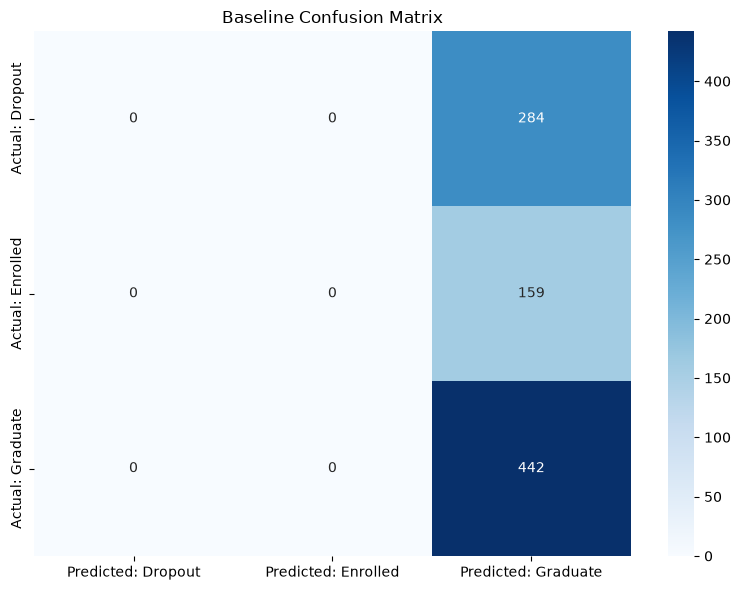

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

class_labels = ["Dropout", "Enrolled", "Graduate"]

cm = confusion_matrix(
    y_test,
    y_pred_baseline,
    labels=class_labels
)

cm_df = pd.DataFrame(
    cm,
    index=[f"Actual: {label}" for label in class_labels],
    columns=[f"Predicted: {label}" for label in class_labels]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_df,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Baseline Confusion Matrix")
plt.tight_layout()
plt.show()

## Baseline Results and Interpretation

The most-frequent-class classifier provides a reference point for later models.

Record the results from the evaluation cells:

- Accuracy: 0.499
- Macro-F1: 0.222
- Dropout recall: 0.00
- Enrolled recall: 0.00
- Graduate recall: 1.00

The baseline predicts the most frequent training class for every test observation. It therefore fails to identify the other two classes.

Later models will be compared against this baseline using the same test set and evaluation metrics. A model will be more useful for this task if it improves performance across the outcome classes rather than merely achieving a higher overall accuracy.